# Layer 2: Mapping (class notes)

**What this layer is, in one line:** it turns a radar picture into a map that shows, for every small square of ground, how likely it is to be a flooded rice field.

You do not need to know how the code is written. You need to be able to explain what each step is, why it is there, and how it leads to the next.

## The story of this layer in one paragraph

Layer 1 gave us radar pictures and the knowledge that flooded ground looks dark. Our first thought is the simplest one: pick a brightness cut-off, and call everything darker than it water (section 3). That works a bit, but it says only yes or no, and it can go badly wrong. So we build two better guessers: one based on hand-written rules (section 4), one learned by a machine-learning model from the marked examples (section 5). Neither is perfect and they fail in different ways, so we blend them (section 6). The blended numbers should be honest probabilities, so we check and, if needed, correct that (section 7). Finally we keep only the rice fields (section 8), score everything (section 9 and 10), and add a rough estimate of flood duration (section 11). Layer 3 uses the result.

## 1. The goal, and what makes a good answer

*Where we are: the start of Layer 2. Input from Layer 1: radar chips with hand-marked water, already split by event.*

For every **20 m by 20 m square (a pixel)**, the map holds a number from 0 to 1: **the probability that this square is a flooded rice field.**

Why a probability and not just yes or no? Because Layer 3 needs to know how sure the map is. A square with 0.95 should be treated very differently from a square with 0.55.

The number must also be **honest**. If the map gives 0.7 to a hundred squares, about 70 of those should really be flooded. Honest probabilities are called **calibrated**. Without this, Layer 3 would trust numbers it should not.

Recall from Layer 1: **VV** and **VH** are two radar readings of the same ground (VV is best for spotting open water, VH responds to plants), on a **dB** scale where lower means darker. Water is dark.

## 2. The recipe as a picture

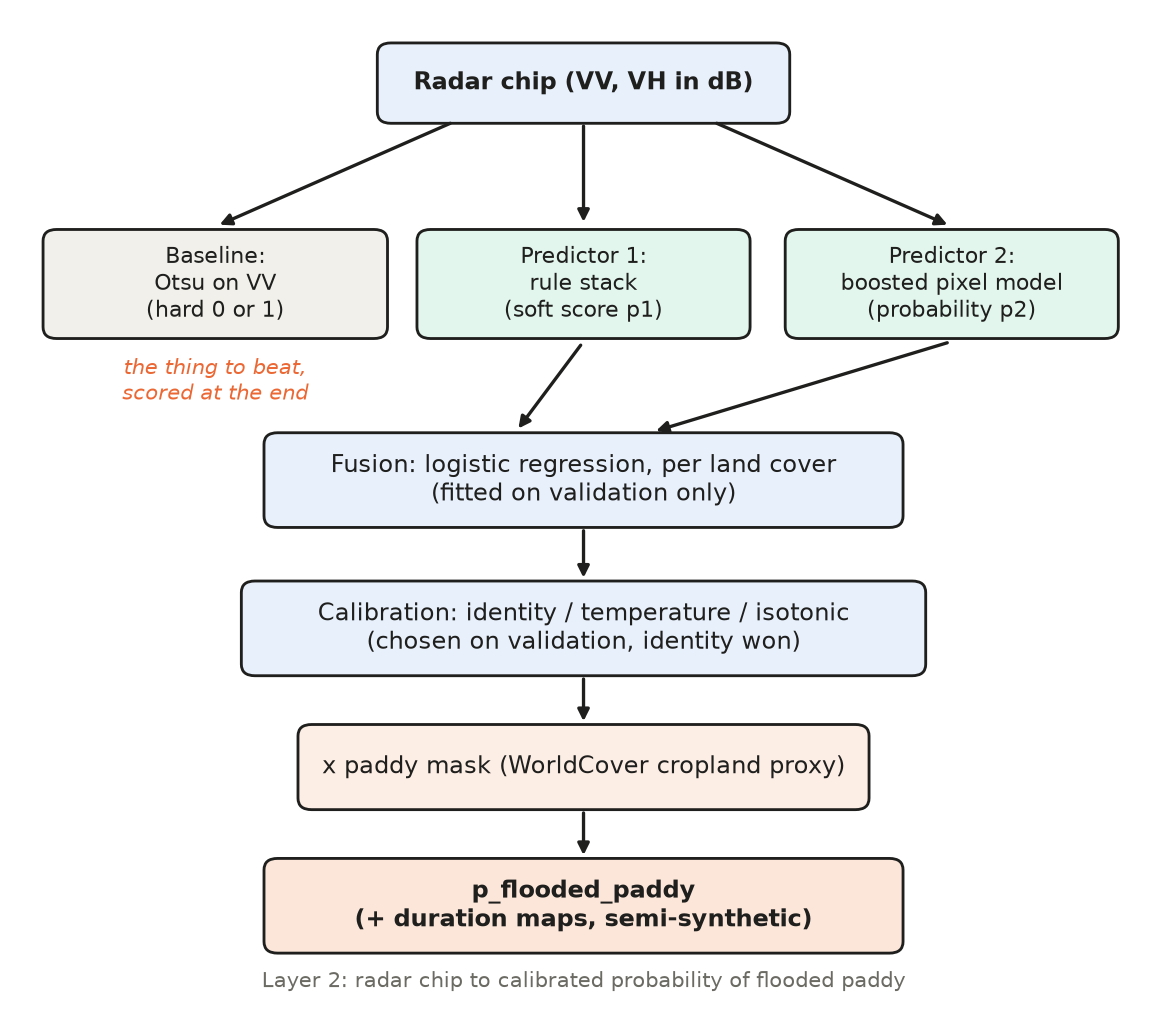

Read it top to bottom:

1. The **radar chip** goes in.
2. The **baseline** (the simplest guess) runs on the side. It is not part of the final map. We keep it so we can show our real methods are better.
3. **Predictor 1** (hand-written rules) and **Predictor 2** (machine-learning model) each make a guess.
4. **Fusion** blends the two into one number.
5. **Calibration** checks and fixes the honesty of that number.
6. The **paddy mask** keeps only rice-field squares.
7. The result is `p_flooded_paddy`.

*The rest of these notes go through the boxes in this order.*

## 3. Which pixels do we even make a call for?

*Where we are: before guessing, we decide what counts.*

Some pixels should not be scored:

* Pixels with **no hand label**: we cannot check them.
* Pixels with **missing radar values**.
* **Permanent water** (rivers and lakes, from a map called JRC). A river is always water, but that is not a flood. If we counted rivers, every method would look better than it deserves, because rivers are easy.

Chips where fewer than **30 percent** of pixels survive this are dropped. From the chips we sampled out of the dataset, **121 usable chips** remain (80 train, 18 validation, 23 test).

*So next: with the pixels settled, we try the simplest possible method.*

## 4. The baseline: Otsu's method

*Where we are: we need something simple to compare against. Without a baseline, "our method scores 0.4" means nothing.*

**Otsu's method** (named after its inventor, Nobuyuki Otsu, pronounced "oh-tsoo"; nothing to do with the game osu) is a classic way to pick **one brightness cut-off** for a picture.

How it works, step by step:

1. Draw a **histogram** of the picture: how many pixels have each brightness.
2. If the picture contains both water and land, the histogram usually has **two humps**: a dark one (water) and a bright one (land).
3. Try every possible cut-off. For each, split the pixels into "darker" and "brighter" groups and measure how tight each group is.
4. Pick the cut-off that makes the two groups as separate and tight as possible. In practice that falls in the valley between the two humps.
5. Call pixels darker than the cut-off water and the rest land.

It is fast and standard, so it makes a fair **baseline**.

**Its weaknesses:**
* It answers only **yes or no**. There is no "maybe", so no probability.
* It assumes **two humps**. If a picture has almost no flood, there is only one hump (all land), and Otsu still forces a cut-off through it, calling a lot of ordinary land water. This is a real failure on dry-ish pictures.

On test events its honesty error is **0.338** (very poor) and its overlap score is **0.190** (explained in section 10).

*So next: we try to do better with rules that guard against these failures.*

## 5. Predictor 1: the rule stack

*Where we are: Otsu fails when there is no clear two-hump picture and it gives no probabilities. A set of rules can fix both.*

This predictor is a checklist, like a rule book an expert would write. It still uses a brightness threshold per picture, but with safeguards:

* **Work in blocks.** The picture is split into blocks of about 50 by 50 pixels, so one dark corner does not distort a threshold used for the whole picture.
* **Check the two humps are real.** A test called **Ashman's D** measures how far apart the two humps are compared with how wide they are. Only if D is at least 3 do we trust a fitted threshold.
* **Fallback thresholds.** If the humps are not clearly separate, use fixed defaults (**-17 dB** for VV, **-22 dB** for VH) instead of a shaky fitted value. In our data only about **19.8 percent of chips** got a fitted threshold. The rest used defaults. That is worth saying out loud.
* **A soft score.** Instead of yes or no, the score is a smooth number between 0 and 1: the further below the threshold a pixel is, the closer it is to 1. (The smooth curve used is called a sigmoid.)

Extra checks using other measurements (like a water index from optical satellite pictures) exist but were idle in our run. We do not claim they helped.

An honest note: on validation events this predictor actually scored better overlap than our final blend (0.491 against 0.356). We report this rather than hide it, and explain it in section 6.

*So next: a completely different style of guesser, one that learns instead of following rules.*

## 6. Predictor 2: the boosted pixel model, and then fusion

*Where we are: Predictor 1 is rule-based. A learned model may spot patterns rules miss.*

**Predictor 2** is a **machine-learning** model. We show it many pixels where we know the label, and it learns which patterns mean water.

* It is a **boosted** model: it is built from many small **decision trees**. A decision tree is a short chain of yes/no questions ("is VV below -16? is the neighbourhood smooth?") ending in a guess. Boosting adds trees one at a time, and each new tree is trained to fix the mistakes of the trees before it. Together they vote.
* Its inputs, called **features**, are 11 numbers per pixel: VV and VH, how bright the surrounding pixels are, how bumpy the surroundings are, and so on.
* To keep training manageable, we sample **4,000 pixels per chip**.
* It is trained **only on the train events**.

**Fusion: blending the two.** Predictor 1 and Predictor 2 make different mistakes, so blending can beat both. The blend is a **logistic regression**: a standard way to turn a weighted combination of numbers into a probability. We use separate weights for each kind of land (trees, crops, towns and so on), because a predictor may be more trustworthy on one kind than another.

**Why fit the blend on validation events, not train?** Predictor 2 has already seen the train events, so on them it looks unrealistically good, and the blend would learn to over-trust it. On validation events both predictors are facing events they were not fitted on, which is the situation they will face in real use. To avoid reusing the same events for both fitting and checking, we use a leave-one-event-out scheme: fit the blend on all validation events but one, check on the one left out, and repeat.

(We do not claim to know exactly why the blend's validation overlap came out below Predictor 1's; we report the numbers as they are.)

*So next: the blend produces a number between 0 and 1. Is it honest?*

## 7. Calibration: are the probabilities honest?

*Where we are: we have one fused probability per pixel. Layer 3 will treat 0.7 as "70 percent sure". We must check that is true.*

**The test.** Sort all pixels into bands by their stated probability (0 to 0.1, 0.1 to 0.2, and so on). In each band, count how many pixels truly were flooded.

**Worked example.** Take all pixels the map gave about 0.7. Suppose there are 1,000. If about 700 really are flooded, the map is honest in that band. If only 500 are, the map is over-confident: it says 70 but means 50.

**ECE (expected calibration error)** is this check done over all bands: the average gap between stated and actual, weighted by how many pixels are in each band. **0 is perfectly honest, and smaller is better.**

**Three fixes we tried**, if the numbers were off:
* **Identity**: leave them alone.
* **Temperature**: stretch or squash all probabilities with one number.
* **Isotonic**: bend them with a flexible curve that only ever rises.

We chose by testing on validation events left out each time. Their honesty errors were about **0.0469** (identity), **0.0554** (temperature) and **0.0990** (isotonic). **Identity won**: the blend was already honest, and fancier fixes added error.

*So next: we have honest probabilities everywhere. The insurance question is only about rice.*

## 8. The paddy mask, and an honest limit

*Where we are: our map covers all land. Insurance is about rice fields.*

The land-cover map we use (**ESA WorldCover**) labels each square as tree, grass, cropland, built-up and so on. **It has no rice class.** So we use **cropland** as a stand-in for paddy, and multiply our flood probability by the mask.

Two consequences to say plainly:
* Cropland includes crops other than rice, so the mask over-includes a little.
* The hand labels mark **water**, not "flooded rice", so some of what we score is flooded land that is not rice.

*So next: how well does all this do?*

## 9. The scores, in plain words

*Where we are: before the results, we need to know what the numbers mean.*

* **ECE**: how dishonest the probabilities are (section 7). Lower is better.
* **Brier score**: the average squared gap between the stated probability and what happened (1 if flooded, 0 if not). Lower is better. A confident wrong answer costs a lot.
* **AUC**: pick a random flooded square and a random dry square; how often does the map give the flooded one the higher number? 1 is perfect, 0.5 is guessing.
* **IoU (overlap score)**: draw the true flooded area and the predicted flooded area. IoU is the area where both agree divided by the area covered by either one. 1 is perfect, 0 means no overlap.

## 10. Results on test events (events not used for fitting)

*Where we are: scored once, at the end, on India and Bolivia.*

| Measure | Our final map | Otsu baseline |
|---|---|---|
| ECE (honesty, lower is better) | **0.0387** | 0.338 |
| IoU (overlap, higher is better) | **0.419** | 0.190 |
| AUC | **0.934** | not applicable (yes or no only) |
| Brier | **0.0627** | not reported |

Flooded area inside the paddy mask on test events: the hand labels say **8.56 km2**, our calibrated map says **5.11 km2** (it under-counts), and Otsu says **16.01 km2** (it over-counts badly). So we beat the baseline a lot, but we are not perfect: our map tends to be conservative on area.

**Honest caveats:**
* Inside the paddy mask alone, our ECE is worse (**0.0992**), so the map is less trustworthy on cropland than overall.
* On validation, Predictor 1 alone had better overlap than the blend (0.491 against 0.356). The blend's strength is in honest probabilities and generalisation, not in beating every single score.

*So next: the last piece of Layer 2 is about time, not space.*

## 11. Duration of flooding (partly simulated)

*Where we are: the map says whether a square is flooded at one moment. Insurance also cares how long.*

Crops survive short floods and die in long ones. A radar chip is one snapshot, so duration cannot be seen directly. We build a **semi-synthetic** duration map: "semi-synthetic" means partly simulated, and we label it so.

* From Layer 1 we know the satellite visits only every few days. So a flood's end is known only as a range. A standard statistical method for range-type data, the **Turnbull estimator**, estimates how likely a field was flooded for at least d days, for **d = 3, 7, 10 and 14**.
* To turn duration into crop damage we use **survival curves** for rice: intolerant rice has half its plants surviving at about **7 days** of full submergence, flood-tolerant "SUB1" varieties at about **14 days**. **These curves are assumptions, not fitted to data.**
* The accuracy check on test events: sensitivity **0.468** and specificity **0.979**. Sensitivity is the share of truly long floods it catches; specificity is the share of short floods it correctly does not call long.

*So next: Layer 3 takes the calibrated map and combines it with field checks.*

## 12. How Layer 2 connects to the others

| Layer 2 produces | Used by |
|---|---|
| calibrated probability per pixel | Layer 3 (as the starting estimate for every field) |
| honest probabilities | Layer 3 (it assumes them to be honest when it computes uncertainty) |
| duration maps | the final report (semi-synthetic) |
| baseline comparison | the evidence that we beat the simple method |

## 13. Key numbers

| Thing | Value |
|---|---|
| Chips used | **121** (80 train, 18 validation, 23 test) |
| Pixel size | 20 m |
| Predictor 1 defaults | **-17 dB** (VV), **-22 dB** (VH); only about **19.8 percent** of chips got a fitted threshold |
| Predictor 2 | boosted trees, **11** features, **4,000** pixels per chip, trained on train events |
| Calibration candidates (honesty error) | identity **0.0469**, temperature 0.0554, isotonic 0.0990; identity won |
| Test, final map | ECE **0.0387**, IoU **0.419**, AUC **0.934**, Brier **0.0627** |
| Test, Otsu baseline | ECE **0.338**, IoU **0.190** |
| Paddy proxy | WorldCover cropland (class 40) |
| Duration levels | d = 3, 7, 10, 14 days; test sensitivity 0.468, specificity 0.979 |

## 14. Glossary

* **Baseline**: a simple method we must beat.
* **Boosting**: building many small decision trees in turn, each fixing the mistakes of the previous ones.
* **Calibrated**: probabilities that match reality (70 percent means about 70 percent).
* **Decision tree**: a short chain of yes/no questions ending in a guess.
* **ECE**: average gap between stated probability and actual frequency.
* **Feature**: a number computed per pixel to help decide.
* **Fusion**: blending several predictors into one.
* **Histogram**: a count of how many pixels have each brightness.
* **IoU**: overlap between predicted and true flooded area.
* **Pixel**: one 20 m by 20 m square.
* **Semi-synthetic**: partly simulated, and labelled so.
* **Threshold**: a cut-off value.
* **VV, VH**: two radar readings; water is dark in VV.

## 15. Review questions

1. **What does Layer 2 do?** Turns a radar picture into a calibrated probability, per pixel, of being a flooded rice field.
2. **Why probabilities and not yes or no?** Layer 3 needs to know how sure each square is.
3. **What is Otsu's method?** A classic way to pick one brightness cut-off by separating the dark hump from the bright hump of a picture's histogram. It is our baseline.
4. **Why does Otsu fail?** It assumes two humps; with little flood there is only one and it cuts through land. It gives no probabilities.
5. **What does Predictor 1 add?** Safeguards: work in blocks, check the humps are separate, fall back to default thresholds, and a soft score.
6. **What is Predictor 2?** A boosted decision-tree model that learns patterns from the labelled train events.
7. **Why blend the two and why fit the blend on validation?** They make different mistakes. Predictor 2 has seen the train events, so its train results look too good.
8. **What is calibration and which fix won?** Making stated probabilities match reality. Leaving them alone (identity) won.
9. **What is ECE?** The average gap between stated probability and actual frequency. Lower is better.
10. **How much better than the baseline?** On test, honesty error fell from 0.338 to 0.0387 and overlap rose from 0.190 to 0.419.
11. **What are the weaknesses?** The paddy mask is a stand-in (cropland); labels are water, not rice; the map under-counts area; inside the mask calibration is worse; on validation Predictor 1 alone had better overlap.
12. **Is the duration part real?** No. It is semi-synthetic, and the crop survival curves are assumptions.